# Markov Decision Process (MDP)

### Ransalu Senanayake

In [2]:
import copy
import timeit
import numpy as np
import matplotlib.pyplot as pl
%matplotlib inline
from ipywidgets import interactive
import ipywidgets as widgets
import time
from collections import defaultdict

Create the following grid world.

**States:** A 10x10 grid

**Actions:** Up, Down, Left, Right

**Tranistion probabilities:**
* 0.7 in the direction of action
* 0.1 in the three other directions
* The robot bounces back to the same state near edges

**Rewards:**
* (7,8) has a reward +10
* (2,7) has a reward +3
* (4,3) has a reward -5
* (7,3) has a reward -10
* No reward in other states

This example is based on Decision Making Under Uncertainty by M.J. Kochenderfer.

In [3]:
#Let's define MDP paras
def createGrid10World():
    def xy2s(y, x):
        x = max(x, 0)
        y = max(y, 0)
        x = min(x, 9)
        y = min(y, 9)
        out = np.ravel_multi_index(np.array([x,y]), (10,10))
        return out

    def s2xy(s):
        x, y = np.unravel_index(s, (10,10))
        return y, x

    def gridPlot(ax, im, title='', cmap='Blues'):
        pl.imshow(im, interpolation='none', cmap=cmap, origin='lower')
        pl.colorbar()
        ax.set_xticks(np.arange(0, 10, 1));
        ax.set_yticks(np.arange(0, 10, 1));
        ax.set_xticklabels(np.arange(0, 10, 1));
        ax.set_yticklabels(np.arange(0, 10, 1));
        ax.set_xticks(np.arange(-.5, 10, 1), minor=True);
        ax.set_yticks(np.arange(-.5, 10, 1), minor=True);
        ax.grid(which='minor', color='w', linestyle='-', linewidth=1)
        pl.title(title);
        return

    A = ['left', 'right', 'up', 'down']
    S = np.arange(100)
    T = np.zeros((len(S), len(A), len(S)))
    R = np.zeros((len(S), len(A)))
    for s in S:
        x, y = s2xy(s)
        if x == 2 and y == 7:
            R[s, :] = 3
        elif x == 7 and y == 8:
            R[s, :] = 10
        else:
            if x == 7 and y == 3:
                R[s, :] = -10
            elif x == 4 and y == 3:
                R[s, :] = -5
            elif x == 0:
                if y == 0 or y == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 0] = -0.7
            elif x == 9:
                if y == 0 or y == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 1] = -0.7
            elif y == 0:
                if x == 0 or x == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 3] = -0.7
            elif y == 9:
                if x == 0 or x == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 2] = -0.7

            for a in A:
                if a == 'left':
                    T[s, 0, xy2s(x - 1, y)] += 0.7
                    T[s, 0, xy2s(x + 1, y)] += 0.1
                    T[s, 0, xy2s(x, y - 1)] += 0.1
                    T[s, 0, xy2s(x, y + 1)] += 0.1
                elif a == 'right':
                    T[s, 1, xy2s(x + 1, y)] += 0.7
                    T[s, 1, xy2s(x - 1, y)] += 0.1
                    T[s, 1, xy2s(x, y - 1)] += 0.1
                    T[s, 1, xy2s(x, y + 1)] += 0.1
                elif a == 'up':
                    T[s, 2, xy2s(x, y + 1)] += 0.7
                    T[s, 2, xy2s(x, y - 1)] += 0.1
                    T[s, 2, xy2s(x - 1, y)] += 0.1
                    T[s, 2, xy2s(x + 1, y)] += 0.1
                elif a == 'down':
                    T[s, 3, xy2s(x, y - 1)] += 0.7
                    T[s, 3, xy2s(x, y + 1)] += 0.1
                    T[s, 3, xy2s(x - 1, y)] += 0.1
                    T[s, 3, xy2s(x + 1, y)] += 0.1

    for a, c_x, c_y in [(0,0,0), (0,0,9),(1,9,0),(1,9,9),(2,0,9),(2,9,9),(3,0,0),(3,9,0)]:
        R[xy2s(c_x,c_y),a] = -0.8

    discount = 0.9

    nextStates = {}
    for si in range(len(S)):
        for ai in range(len(A)):
            nextStates[(si,ai)] = np.where((T[si, ai, :] != 0) == True)[0]

    return {'S':S, 'A':A, 'T':T, 'R':R, 'discount':discount, 'nextStates':nextStates, 'gridPlot':gridPlot, 'xy2s':xy2s, 's2xy':s2xy}

In [4]:
class MDP():
    def __init__(self):
        pass

    def inbuilt_init(self, mdp_dict):
        self.S = mdp_dict['S']
        self.A = mdp_dict['A']
        self.T = mdp_dict['T']
        self.R = mdp_dict['R']
        self.discount = mdp_dict['discount']
        self.nextStates = mdp_dict['nextStates']
        self.gridPlot = mdp_dict['gridPlot']
        self.xy2s = mdp_dict['xy2s']
        self.s2xy = mdp_dict['s2xy']

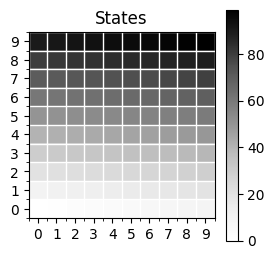

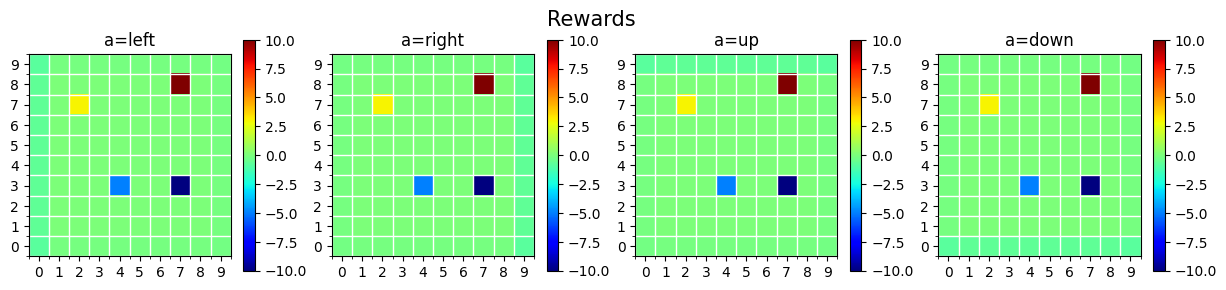

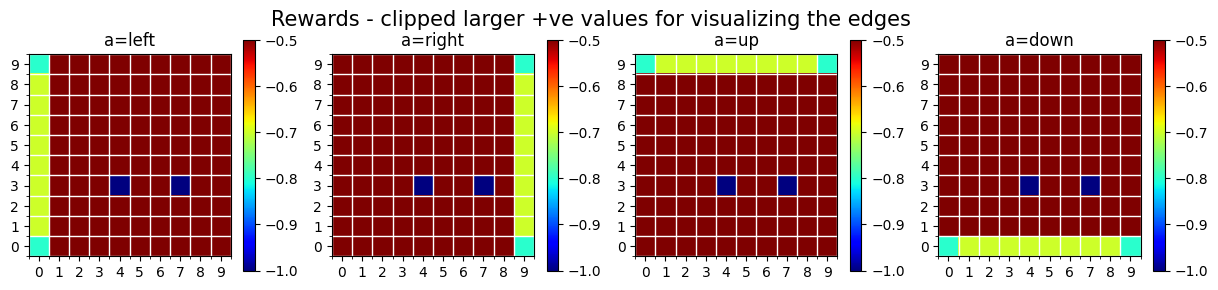

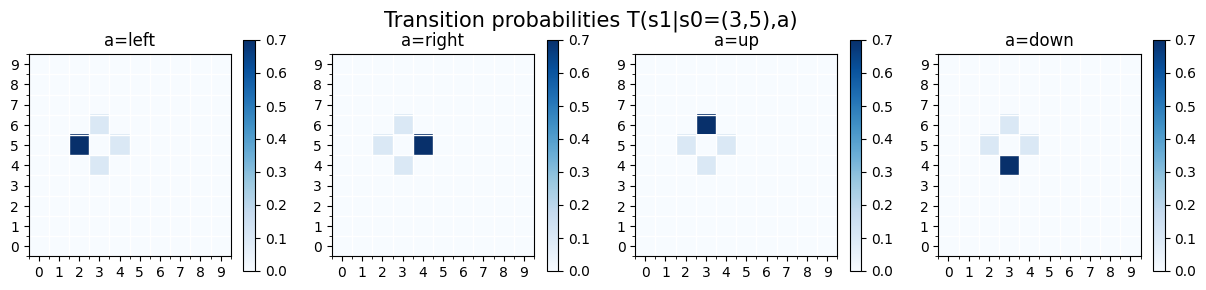

In [5]:
#Define the MDP
mdp = MDP()
mdp.inbuilt_init(mdp_dict=createGrid10World())

#Plot states
pl.figure(figsize=(3,3))
mdp.gridPlot(ax=pl.gca(), im=mdp.S.reshape((10,10)), title='States', cmap='Greys')

#Plot rewards
pl.figure(figsize=(15,3))
pl.suptitle('Rewards', fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    mdp.gridPlot(ax=pl.gca(), im=mdp.R[:,a].reshape((10,10)), title='a='+mdp.A[a], cmap='jet')
pl.show()

#Plot rewards
pl.figure(figsize=(15,3))
pl.suptitle('Rewards - clipped larger +ve values for visualizing the edges', fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    mdp.gridPlot(ax=pl.gca(), im=np.clip(mdp.R[:,a].reshape((10,10)), -1, -0.5), title='a='+mdp.A[a], cmap='jet')
pl.show()

#Plot rewards
s0_x, s0_y = 3, 5
s0 = mdp.xy2s(s0_x, s0_y)
pl.figure(figsize=(15,3))
pl.suptitle('Transition probabilities T(s1|s0=({},{}),a)'.format(s0_x, s0_y), fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    mdp.gridPlot(ax=pl.gca(), im=mdp.T[s0,a,:].reshape((10,10)), title='a='+mdp.A[a], cmap='Blues')
pl.show()

In [6]:
#An interactive plot of transition probabilities
def f(s0_x, s0_y, action):
    a = mdp.A.index(action)
    s0 = mdp.xy2s(int(s0_x), int(s0_y))
    pl.figure(figsize=(6,6))
    title = 'Transition probabilities T(s1|s0=({},{}),a={})'.format(int(s0_x),int(s0_y),action)
    mdp.gridPlot(ax=pl.gca(), im=mdp.T[s0,a,:].reshape((10,10)), title=title, cmap='Blues')
    pl.show()

interactive_plot = interactive(f, s0_x='4', s0_y='5', action=widgets.ToggleButtons(options=['left', 'right', 'up', 'down']))
interactive_plot

interactive(children=(Text(value='4', description='s0_x'), Text(value='5', description='s0_y'), ToggleButtons(…

### 1. Policy evaluation

Computing the utility, U.

$U^\pi_k(s) = R(s, \pi(s)) + \gamma \sum_{s'} T(s' \mid s, \pi(s))U^\pi_{k-1}(s')$

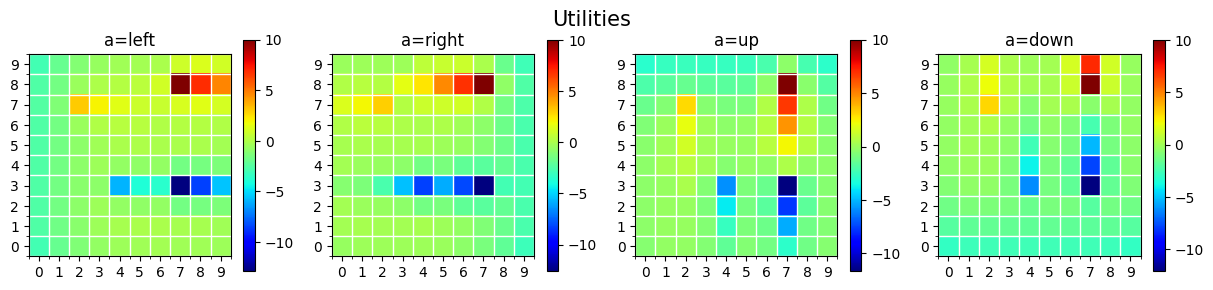

In [7]:
def iterativePolicyEvaluation(mdp, policy, numIterations=10):
    U = np.zeros(len(mdp.S))
    U_old = copy.copy(U)
    for t in range(numIterations):
        for s in range(len(mdp.S)):
            if isinstance(policy, int):
                a = policy
            else:
                a = policy[s]

            immediate_reward = mdp.R[s, a]

            future_reward = 0
            for s_next in range(len(mdp.S)):
                future_reward += mdp.T[s, a, s_next] * U_old[s_next]

            U[s] = immediate_reward + mdp.discount * future_reward

        U_old = copy.copy(U)
    return U

numIterations = 5
pl.figure(figsize=(15,3))
pl.suptitle('Utilities', fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    U = iterativePolicyEvaluation(mdp=mdp, policy=a, numIterations=numIterations)
    mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='a='+mdp.A[a], cmap='jet')
pl.show()
#print(np.round(U.reshape(10,10),3))

In [8]:
def f(action, numIter=1):
    U = iterativePolicyEvaluation(mdp, policy=mdp.A.index(action), numIterations=numIter)
    pl.figure(figsize=(3,3))
    mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='Utility', cmap='jet')
    pl.show()

interactive_plot = interactive(f, action=widgets.ToggleButtons(options=['left', 'right', 'up', 'down']),
                               numIter=widgets.IntSlider(min=0, max=20, step=1, value=0))
interactive_plot

interactive(children=(ToggleButtons(description='action', options=('left', 'right', 'up', 'down'), value='left…

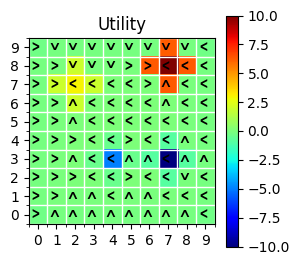

In [28]:
#Value iteration
def valueIteration(mdp, numIterations=1):
    U = np.zeros(len(mdp.S))
    U_old = copy.copy(U)
    for t in range(numIterations):
        for s in range(len(mdp.S)):
            action_values = np.zeros(len(mdp.A))

            for a in range(len(mdp.A)):
                immediate_reward = mdp.R[s, a]

                future_reward = 0
                for s_next in range(len(mdp.S)):
                    future_reward += mdp.T[s, a, s_next] * U_old[s_next]

                action_values[a] = immediate_reward + mdp.discount * future_reward

            U[s] = np.max(action_values)

        U_old = copy.copy(U)
    return U

def policyExtration(mdp, U):
    policy = np.zeros(len(mdp.S))
    for s in range(len(mdp.S)):
        action_values = np.zeros(len(mdp.A))

        for a in range(len(mdp.A)):
            future_value = 0
            for s_next in range(len(mdp.S)):
                future_value += mdp.T[s, a, s_next] * U[s_next]

            action_values[a] = mdp.R[s, a] + mdp.discount * future_value

        policy[s] = np.argmax(action_values)
    return policy

U = valueIteration(mdp, numIterations=2)
policy = policyExtration(mdp, U=U)
pl.figure(figsize=(3,3))
mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='Utility', cmap='jet')
for s in range(100):
    x, y = mdp.s2xy(s)
    if policy[s] == 0:
        m='\u02C2'
    elif policy[s] == 1:
        m='\u02C3'
    elif policy[s] == 2:
        m='\u02C4'
    elif policy[s] == 3:
        m='\u02C5'
    pl.text(x-0.5,y-1,m,color='k',size=20)
pl.show()

def valueIteration_convergence(mdp, numIterations=50, tol=1e-6):
    U = np.zeros(len(mdp.S))
    convergence = []
    for t in range(numIterations):
        U_new = np.copy(U)
        for s in range(len(mdp.S)):
            action_values = np.zeros(len(mdp.A))
            for a in range(len(mdp.A)):
                future_reward = np.dot(mdp.T[s, a, :], U)
                action_values[a] = mdp.R[s, a] + mdp.discount * future_reward
            U_new[s] = np.max(action_values)
        delta = np.max(np.abs(U_new - U))
        convergence.append(delta)
        U = U_new
        if delta < tol:
            break
    policy = policyExtration(mdp, U)
    return U, policy, convergence


In [10]:
def f(numIter=1):
    start_time = timeit.default_timer()
    U = valueIteration(mdp, numIterations=numIter)
    policy = policyExtration(mdp, U=U)
    elapsed = timeit.default_timer() - start_time
    print('time=', np.round(elapsed*1000,2))
    pl.figure(figsize=(3,3))
    mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='Utility', cmap='jet')
    for s in range(100):
        x, y = mdp.s2xy(s)
        if policy[s] == 0:
            m='\u02C2'
        elif policy[s] == 1:
            m='\u02C3'
        elif policy[s] == 2:
            m='\u02C4'
        elif policy[s] == 3:
            m='\u02C5'
        pl.text(x-0.5,y-1,m,color='k',size=20)
    pl.show()

interactive_plot = interactive(f, numIter=widgets.IntSlider(min=0, max=20, step=1, value=0))
interactive_plot

interactive(children=(IntSlider(value=0, description='numIter', max=20), Output()), _dom_classes=('widget-inte…

### 2. Policy iteration

Policy evaluation can be used in policy iteration:
1. Given the current policy, compute U
2. Using U, compute a new policy

In [11]:
def policyIteration(mdp, numIterations=1):
    U_pi_k = np.zeros(len(mdp.S)) #initial values
    pi_k = np.random.randint(low=0,high=4,size=len(mdp.S),dtype=int) #initial policy
    pi_kp1 = copy.copy(pi_k)
    for t in range(numIterations):
        U_old = np.zeros(len(mdp.S))
        U_pi_k = np.zeros(len(mdp.S))

        for eval_iter in range(100):
            for s in range(len(mdp.S)):
                a = pi_k[s]

                immediate_reward = mdp.R[s, a]

                future_reward = 0
                for s_next in range(len(mdp.S)):
                    future_reward += mdp.T[s, a, s_next] * U_old[s_next]

                U_pi_k[s] = immediate_reward + mdp.discount * future_reward
            if np.max(np.abs(U_pi_k - U_old)) < 1e-6:
                break

            U_old = copy.copy(U_pi_k)

        for s in range(len(mdp.S)):
            action_values = np.zeros(len(mdp.A))

            for a in range(len(mdp.A)):
                future_value = 0
                for s_next in range(len(mdp.S)):
                    future_value += mdp.T[s, a, s_next] * U_pi_k[s_next]

                action_values[a] = mdp.R[s, a] + mdp.discount * future_value

            pi_kp1[s] = np.argmax(action_values)

        pi_k = copy.copy(pi_kp1)
    return U_pi_k, pi_kp1

U_pi_k, pi_kp1 = policyIteration(mdp, numIterations=2)

In [12]:
def f(numIter=1):
    start_time = timeit.default_timer()
    # code you want to evaluate
    value, policy = policyIteration(mdp, numIterations=numIter)
    elapsed = timeit.default_timer() - start_time
    print('time=', np.round(elapsed*1000,2))
    pl.figure(figsize=(3,3))
    mdp.gridPlot(ax=pl.gca(), im=value.reshape(10,10), title='Utility', cmap='jet')
    for s in range(100):
        x, y = mdp.s2xy(s)
        if policy[s] == 0:
            m='\u02C2'
        elif policy[s] == 1:
            m='\u02C3'
        elif policy[s] == 2:
            m='\u02C4'
        elif policy[s] == 3:
            m='\u02C5'
        pl.text(x-0.5,y-1,m,color='k',size=20)
    pl.show()

interactive_plot = interactive(f, numIter=widgets.IntSlider(min=0, max=20, step=1, value=0))
interactive_plot

interactive(children=(IntSlider(value=0, description='numIter', max=20), Output()), _dom_classes=('widget-inte…

In [30]:
# implmenting Q-learning

def q_learning(mdp, episodes=5000, alpha=0.1, gamma=0.9, epsilon=0.1):
    Q = np.zeros((len(mdp.S), len(mdp.A)))
    rewards_per_episode = []

    for episode in range(episodes):
        state = np.random.choice(mdp.S)  # start from random state
        total_reward = 0

        for _ in range(100):  # max steps per episode
            # ε-greedy action selection
            if np.random.rand() < epsilon:
                action = np.random.choice(len(mdp.A))
            else:
                action = np.argmax(Q[state])

            # Transition: normalize probabilities
            next_state_probs = mdp.T[state, action, :]
            if next_state_probs.sum() == 0:
                next_state = state
            else:
                next_state_probs = next_state_probs / next_state_probs.sum()
                next_state = np.random.choice(mdp.S, p=next_state_probs)

            reward = mdp.R[state, action]
            total_reward += reward

            # Q-learning update
            best_next_action = np.argmax(Q[next_state])
            td_target = reward + gamma * Q[next_state, best_next_action]
            Q[state, action] += alpha * (td_target - Q[state, action])

            state = next_state

        rewards_per_episode.append(total_reward)

    # Extract policy and value function
    policy = np.argmax(Q, axis=1)
    V = np.max(Q, axis=1)
    return Q, policy, V, rewards_per_episode

    # Running average of rewards
window = 100
avg_rewards = np.convolve(rewards, np.ones(window)/window, mode='valid')



Value Iteration Time: 1.542 s
Q-Learning Time: 9.369 s


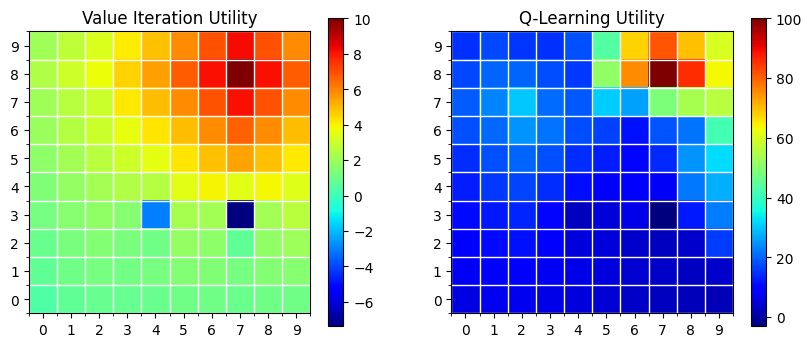

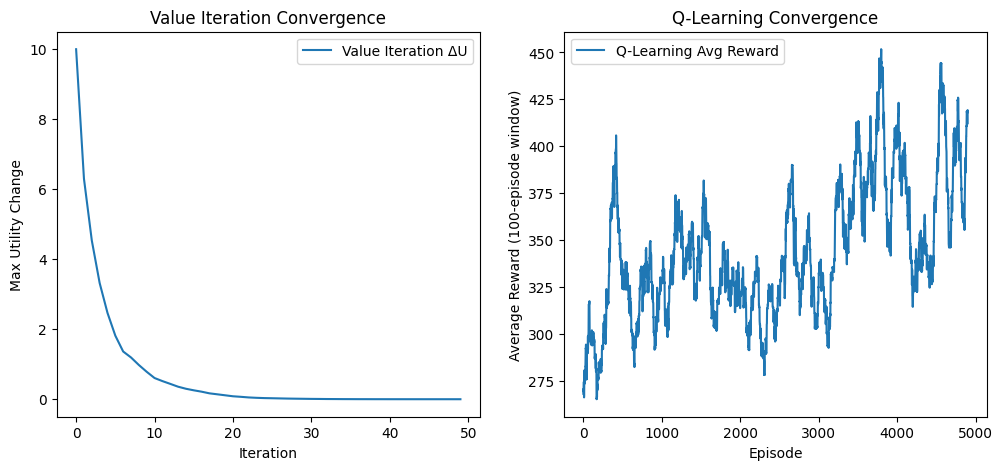

In [32]:
# Time and convergence difference visualization in both approaches

# --- Model-Based (Value Iteration) ---
start_vi = timeit.default_timer()
U_vi = valueIteration(mdp, numIterations=50)
policy_vi = policyExtration(mdp, U=U_vi)
time_vi = timeit.default_timer() - start_vi
print("Value Iteration Time:", round(time_vi, 3), "s")

# --- Model-Free (Q-Learning) ---
start_ql = timeit.default_timer()
Q, policy_ql, V_ql, rewards = q_learning(mdp, episodes=5000)
time_ql = timeit.default_timer() - start_ql
print("Q-Learning Time:", round(time_ql, 3), "s")

# --- Plot and Compare ---
pl.figure(figsize=(10,4))
pl.subplot(1,2,1)
mdp.gridPlot(ax=pl.gca(), im=U_vi.reshape(10,10), title='Value Iteration Utility', cmap='jet')

pl.subplot(1,2,2)
mdp.gridPlot(ax=pl.gca(), im=V_ql.reshape(10,10), title='Q-Learning Utility', cmap='jet')
pl.show()

# --- Run Value Iteration ---
U_vi, policy_vi, conv_vi = valueIteration_convergence(mdp, numIterations=50)

# --- Run Q-Learning ---
Q, policy_ql, V_ql, rewards = q_learning(mdp, episodes=5000)

# --- Time comparison already printed ---

# --- Convergence Plots ---
pl.figure(figsize=(12,5))

pl.subplot(1,2,1)
pl.plot(conv_vi, label="Value Iteration ΔU")
pl.xlabel("Iteration")
pl.ylabel("Max Utility Change")
pl.title("Value Iteration Convergence")
pl.legend()

pl.subplot(1,2,2)
avg_rewards = np.convolve(rewards, np.ones(100)/100, mode='valid')
pl.plot(avg_rewards, label="Q-Learning Avg Reward")
pl.xlabel("Episode")
pl.ylabel("Average Reward (100-episode window)")
pl.title("Q-Learning Convergence")
pl.legend()

pl.show()


In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Modified Policy Evaluation code

![](https://drive.google.com/uc?export=view&id=15cZFhNybF-7NQVVjFIe0MYs6lJZoaQmM)


Modified Value iteraction and policy extraction code

![](https://drive.google.com/uc?export=view&id=1aGfxXaocJ6qL3CHO7SJiP9R6mSHmrP-V)


Modified policy iteration code

![](https://drive.google.com/uc?export=view&id=14ZxqJvHPQj3LaAWGk9SyESt-d0AvS8Kq)

Difference in Time and Convergence in both approaches

![](https://drive.google.com/uc?export=view&id=11-eyRneuayFamy7bI5VwRZ9YQ1rztAVk)

# The difference between Model-Based and Model-Free algorithms


*   In Model based, The agent knows (or learns) the model of the environment such as in the transition probabilities and the reward function. It uses planning algorithms like Value Iteration or Policy Iteration to compute the optimal policy by simulating outcomes.

*   In Model-Free RL, The agent does not know the transition or reward models. It learns directly from experience (interacting with the environment) as in trial-and-error methods like Q-Learning or SARSA, updating value estimates based on observed rewards and transitions.